В этом соревновании вам предстоит предсказать вероятность того, что онлайн-транзакция является мошеннической, о чем свидетельствует бинарный целевой признак isFraud.

 Данные разбиты на два файла: identity и transaction, которые объединены по ключу TransactionID. Не все транзакции имеют соответствующую идентификационную информацию.

 Категориальные признаки — транзакция

ProductCD

card1 — card6

addr1, addr2

P_emaildomain

R_emaildomain

M1 — M9

 Категориальные признаки — идентификационные данные

DeviceType

DeviceInfo

id_12 — id_38

 Признак TransactionDT представляет собой разницу во времени между заданной опорной датой и временем (а не фактическую временную метку).

 Подробнее о данных можно прочитать в этом посте организатора соревнования.

 Файлы
train_{transaction, identity}.csv — обучающая выборка

test_{transaction, identity}.csv — тестовая выборка (вам нужно предсказать значение isFraud для этих наблюдений)

sample_submission.csv — пример файла для отправки в правильном формате

In [1]:
import pandas as pd
import numpy as np
import zipfile
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
import os
print("Текущая директория:", os.getcwd())
print("Файлы в ней:", os.listdir())

Текущая директория: /kaggle/working
Файлы в ней: ['__notebook__.ipynb']


### **Загрузка данных**

In [2]:
import kagglehub
path = kagglehub.competition_download("ieee-fraud-detection")
print("Path to dataset files:", path)

Path to dataset files: /kaggle/input/competitions/ieee-fraud-detection


In [3]:
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/competitions/ieee-fraud-detection/sample_submission.csv
/kaggle/input/competitions/ieee-fraud-detection/test_identity.csv
/kaggle/input/competitions/ieee-fraud-detection/train_identity.csv
/kaggle/input/competitions/ieee-fraud-detection/test_transaction.csv
/kaggle/input/competitions/ieee-fraud-detection/train_transaction.csv


In [4]:
train_identity = pd.read_csv("/kaggle/input/competitions/ieee-fraud-detection/train_identity.csv")
test_identity = pd.read_csv("/kaggle/input/competitions/ieee-fraud-detection/test_identity.csv")
train_transaction = pd.read_csv("/kaggle/input/competitions/ieee-fraud-detection/train_transaction.csv")
test_transaction =  pd.read_csv("/kaggle/input/competitions/ieee-fraud-detection/test_transaction.csv")

In [5]:
# объединю файлы для удобства работы
train_data = pd.merge(train_transaction, train_identity, on="TransactionID", how="left")
test_data = pd.merge(test_transaction, test_identity, on="TransactionID", how="left")

In [6]:
print(f'В тренировачном датасете : {train_data.shape[0]} строк и {train_data.shape[1]} колонок.')
print(f'В тестовом датасете {test_data.shape[0]} строк и {test_data.shape[1]} колонок.')

В тренировачном датасете : 590540 строк и 434 колонок.
В тестовом датасете 506691 строк и 433 колонок.


### **EDA (Exploration Data Analysis)**

In [7]:
train_data.head(5)

,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,...,id_31,id_32,id_33,id_34,id_35,id_36,id_37,id_38,DeviceType,DeviceInfo
0,2987000,0,86400,68.5,W,13926,NaN,150.0,discover,142.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2987001,0,86401,29.0,W,2755,404.0,150.0,mastercard,102.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2987002,0,86469,59.0,W,4663,490.0,150.0,visa,166.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2987003,0,86499,50.0,W,18132,567.0,150.0,mastercard,117.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2987004,0,86506,50.0,H,4497,514.0,150.0,mastercard,102.0,...,samsung browser 6.2,32.0,2220x1080,match_status:2,T,F,T,T,mobile,SAMSUNG SM-G892A Build/NRD90M


In [8]:
test_data.head(5)

,TransactionID,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,card6,...,id-31,id-32,id-33,id-34,id-35,id-36,id-37,id-38,DeviceType,DeviceInfo
0,3663549,18403224,31.95,W,10409,111.0,150.0,visa,226.0,debit,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,3663550,18403263,49.00,W,4272,111.0,150.0,visa,226.0,debit,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3663551,18403310,171.00,W,4476,574.0,150.0,visa,226.0,debit,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3663552,18403310,284.95,W,10989,360.0,150.0,visa,166.0,debit,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,3663553,18403317,67.95,W,18018,452.0,150.0,mastercard,117.0,debit,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [9]:
train_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 590540 entries, 0 to 590539
Columns: 434 entries, TransactionID to DeviceInfo
dtypes: float64(399), int64(4), object(31)
memory usage: 1.9+ GB


In [10]:
#train_data.describe()

По первому впечатлению данные содержат непрерывные и дискретные переменные. В столбце TransactionID, TransactionDT имеются слишком большие значения.
Если посмотреть еа card1, card2, card3, то можно увидеть, что данные линейно возрастают.Особенно это видно, если посмотреть на 25% и 75 квантиль.
Имееться очень большой разброс. Среднее > стандартное отклонение, следовательно, данные смещены вправо.

In [11]:
print(f" Всего пустых значений: {train_data.isnull().any().sum()}")

 Всего пустых значений: 414


In [12]:
# проверю наличие константных признаков в столбцах в обучающей и тестовой выборке
constant_cols_train = [col for col in train_data.columns if train_data[col].nunique() <= 1]

print(f"Найдено константных столбцов: {len(constant_cols_train)}")
print("Список:", constant_cols_train)

Найдено константных столбцов: 0
Список: []


In [13]:
constant_cols_test = [col for col in test_data.columns if test_data[col].nunique() <= 1]

print(f"Найдено константных столбцов: {len(constant_cols_test)}")
print("Список:", constant_cols_test)
# нельзя удалять только из теста, так как данные станут несовместимыми

Найдено константных столбцов: 1
Список: ['V107']


### **Визуализация**

#### **Распределение целевой переменной Y**

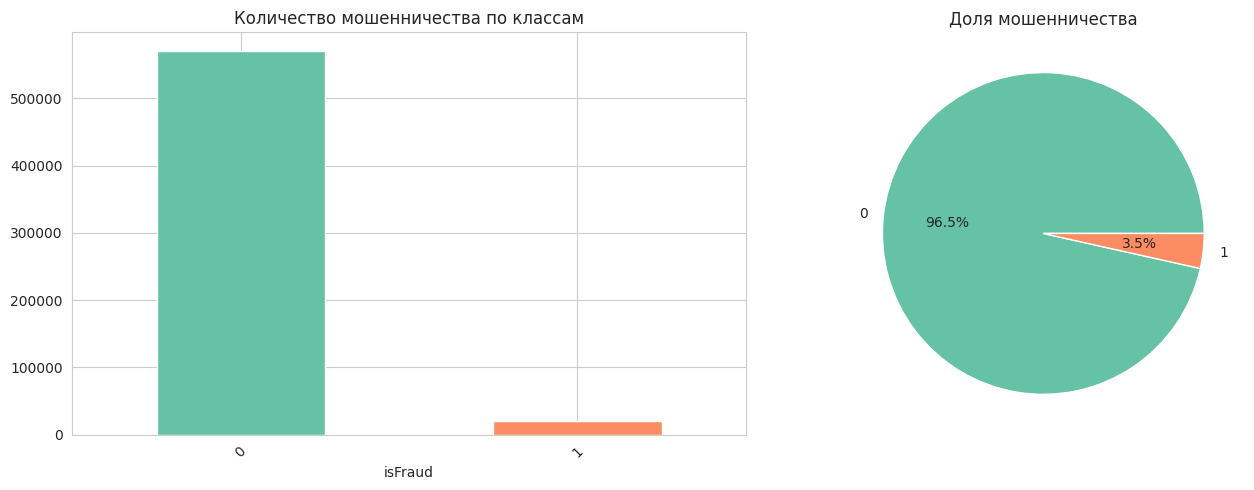

In [14]:
target_col = 'isFraud'
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

train_data[target_col].value_counts().plot.bar(ax=axes[0], color=sns.color_palette('Set2'))
axes[0].set_title('Количество мошенничества по классам')
axes[0].tick_params(axis='x', rotation=45)

train_data[target_col].value_counts(normalize=True).plot.pie(ax=axes[1], autopct='%1.1f%%', colors=sns.color_palette('Set2'))
axes[1].set_ylabel('')
axes[1].set_title('Доля мошенничества')
plt.tight_layout()
plt.show()

Стандартная проблема в этой ситуации - это неравномерное распредление классов. Это можно исправить путем добавление миноритарных классов.

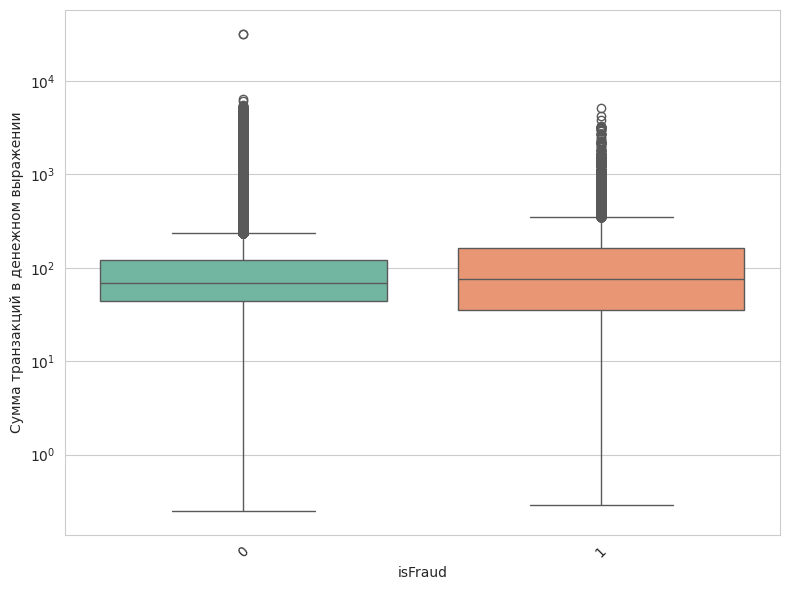

In [15]:
fig, ax = plt.subplots(1, 1, figsize=(8, 6))
sns.boxplot(data=train_data, x='isFraud', y='TransactionAmt', palette='Set2')
ax.tick_params(axis='x', rotation=45)
plt.yscale('log')
plt.ylabel('Сумма транзакций в денежном выражении')
plt.tight_layout()
plt.show()

**TransactionAmt** - сумма транзакции в денежном выражении. Это один из самых сильных и информативных признаков, так как мошеннические транзакции часто имеют аномальные суммы (либо очень маленькие для "проверки" карты, либо очень большие). При работе с этой колонкой часто применяют логарифмическое преобразование, так как распределение сумм сильно скошено в сторону больших значений.

По графику Box-plot можно заметить, что аномальных выбросов очень много относительно целевой переменной. Однако мошенники могут также использовать мелкие суммы для того, чтобы проверить, прошла ли транзакция.

**TransactionDT** - это временная метка (время транзакции). Однако это не обычная дата и время. Это относительное время, измеренное в секундах от начала отсчета (которое неизвестно). Другими словами:

У первой транзакции в датасете значение будет близко к 0.
У каждой следующей транзакции значение увеличивается на количество секунд, прошедших с момента первой.

Пример: Если у транзакции TransactionDT = 86400, значит, она произошла ровно через 1 сутки (24 часа) после самой первой транзакции в наборе данных. Это позволяет анализировать последовательность событий во времени, но не дает реальной даты (день недели, месяц, год). Часто из этой колонки вычисляют производные признаки, например Hour (час транзакции) или Day (день с начала отсчета).

Разделение TransactionDT на:

- циклические признаки
- дни недели
- выходной или ночь

In [16]:
# Извлекаю базовые временные признаки из TransactionDT
def extract_time_features(df):
    # часы от начала отсчета (0-23)
    df['TransactionHour'] = (df['TransactionDT'] / 3600) % 24
    # дни от начала отсчета
    df['TransactionDay'] = df['TransactionDT'] // (3600 * 24)
    # день недели (0-6, где 0 - условный понедельник)
    df['TransactionDayOfWeek'] = (df['TransactionDT'] // (3600 * 24)) % 7
    #  бинарный признак (0 или 1), который показывает, является ли день транзакции выходным и ночью
    df['IsWeekend'] = ((df['TransactionDayOfWeek'] >= 5) |
                       (df['TransactionDayOfWeek'] <= 1)).astype(int)
    df['IsNight'] = ((df['TransactionHour'] >= 22) |
                     (df['TransactionHour'] <= 5)).astype(int)

    return df

# Применяю
train_data = extract_time_features(train_data)
test_data = extract_time_features(test_data)

In [17]:
time_features = ['TransactionHour', 'TransactionDay', 'TransactionDayOfWeek', 'IsWeekend', 'IsNight']
print("\nПроверка наличия колонок:")
for col in time_features:
    print(f"  {col}: {col in train_data.columns}")


Проверка наличия колонок:
  TransactionHour: True
  TransactionDay: True
  TransactionDayOfWeek: True
  IsWeekend: True
  IsNight: True


1. В выходные люди меньше следят за транзакциями (расслаблены)
2. Мошенники знают, что банки работают хуже в выходные
3. Онлайн-покупок в выходные больше, а значит, больше возможностей для мошенничества
4. Мошенники часто активны ночью (с 22:00 до 04:00).

In [18]:
print(train_data.columns.tolist())

['TransactionID', 'isFraud', 'TransactionDT', 'TransactionAmt', 'ProductCD', 'card1', 'card2', 'card3', 'card4', 'card5', 'card6', 'addr1', 'addr2', 'dist1', 'dist2', 'P_emaildomain', 'R_emaildomain', 'C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'C8', 'C9', 'C10', 'C11', 'C12', 'C13', 'C14', 'D1', 'D2', 'D3', 'D4', 'D5', 'D6', 'D7', 'D8', 'D9', 'D10', 'D11', 'D12', 'D13', 'D14', 'D15', 'M1', 'M2', 'M3', 'M4', 'M5', 'M6', 'M7', 'M8', 'M9', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'V29', 'V30', 'V31', 'V32', 'V33', 'V34', 'V35', 'V36', 'V37', 'V38', 'V39', 'V40', 'V41', 'V42', 'V43', 'V44', 'V45', 'V46', 'V47', 'V48', 'V49', 'V50', 'V51', 'V52', 'V53', 'V54', 'V55', 'V56', 'V57', 'V58', 'V59', 'V60', 'V61', 'V62', 'V63', 'V64', 'V65', 'V66', 'V67', 'V68', 'V69', 'V70', 'V71', 'V72', 'V73', 'V74', 'V75', 'V76', 'V77', 'V78', 'V79', 'V80', 'V81', 'V

#### **Анализ времени**

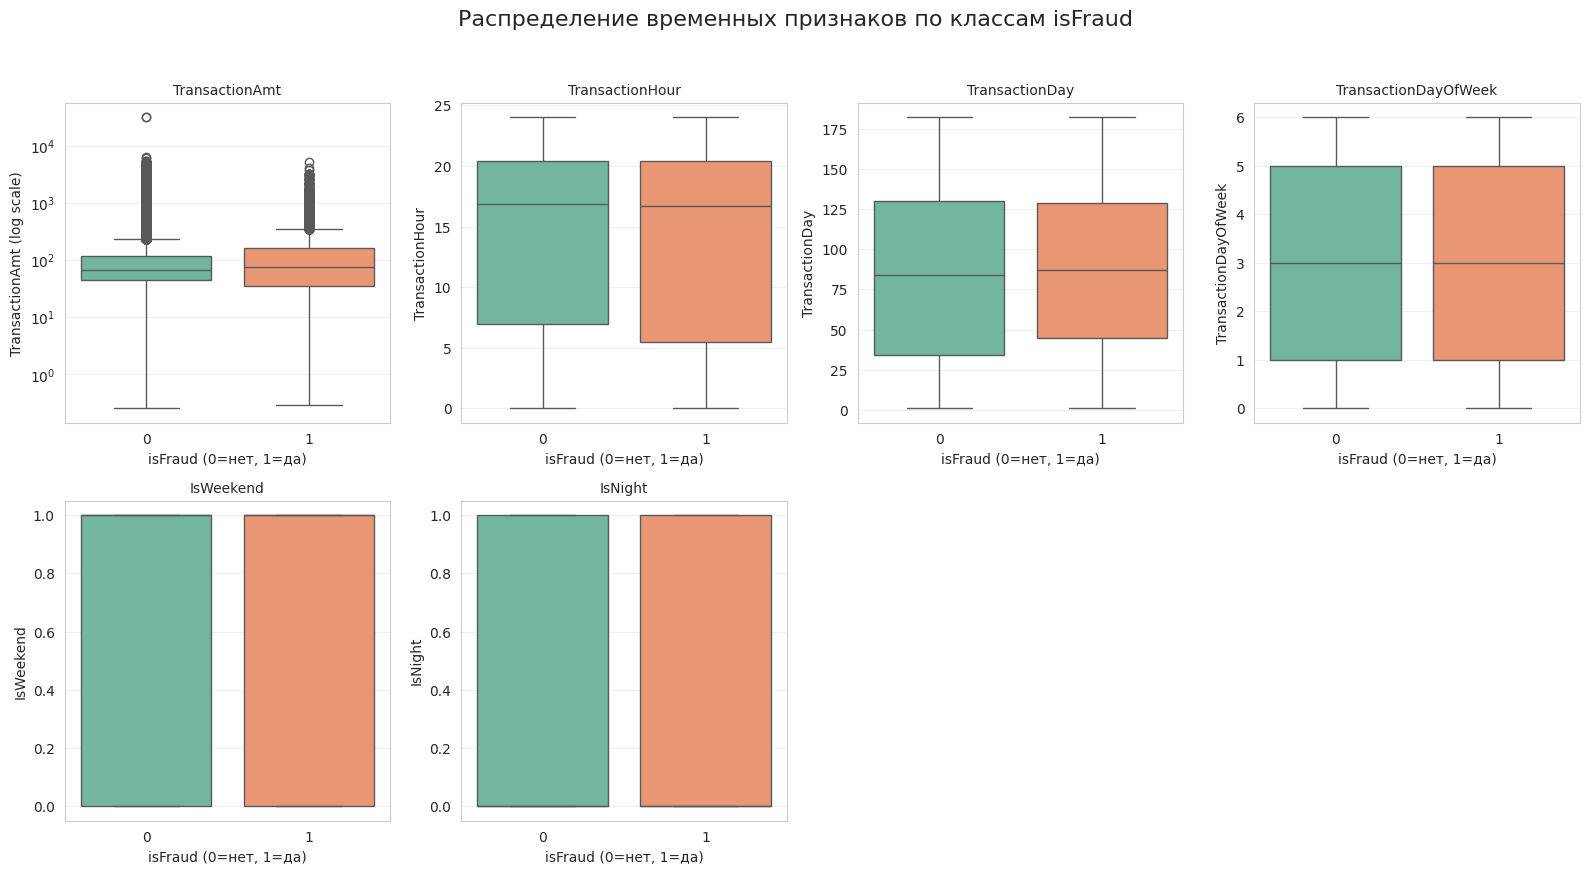

In [19]:
# признаки (без isFraud)
time_features = ['TransactionAmt', 'TransactionHour', 'TransactionDay', 'TransactionDayOfWeek','IsWeekend', 'IsNight']

fig, axes = plt.subplots(3, 4, figsize=(16, 12))
axes = axes.flatten()

for idx, feature in enumerate(time_features):
    ax = axes[idx]

    # Boxplot по классам
    sns.boxplot(data=train_data, x='isFraud', y=feature, ax=ax, palette='Set2')

    # для суммы транзакций используем логарифмическую шкалу
    if feature == 'TransactionAmt':
        ax.set_yscale('log')
        ax.set_ylabel('TransactionAmt (log scale)')

    ax.set_title(f'{feature}', fontsize=10)
    ax.set_xlabel('isFraud (0=нет, 1=да)')
    ax.grid(axis='y', alpha=0.3)

# убираем лишние пустые графики (если есть)
for idx in range(len(time_features), len(axes)):
    fig.delaxes(axes[idx])

plt.suptitle('Распределение временных признаков по классам isFraud', fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

Мошенники делают две категории сумм:
1. Очень маленькие ($2-3) — "проверка" карты

2. Средние ($50-100) — основные мошеннические транзакции

3. Обычные пользователи чаще всего тратят $10-20

#### **Доля совершенных мошеннических транзакций ночью/днем**

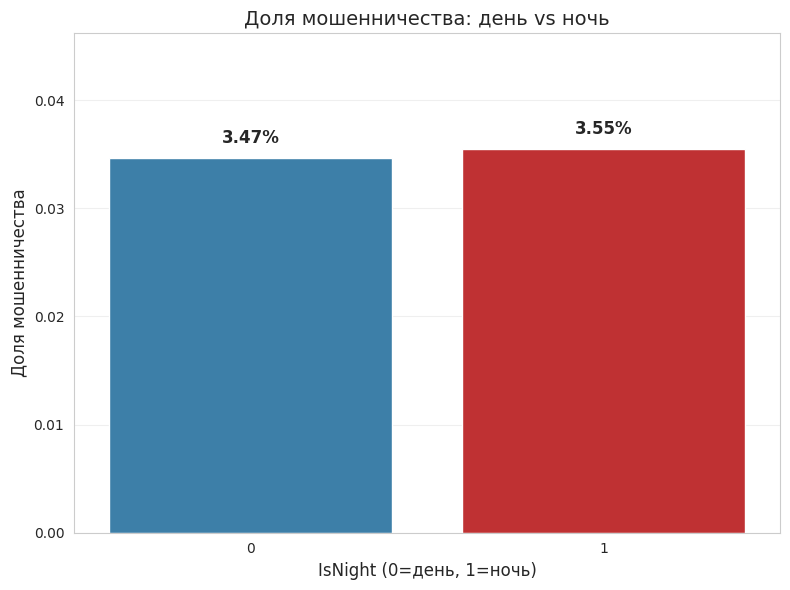

In [20]:
fig, ax = plt.subplots(1, 1, figsize=(8, 6))

# Доля мошенничества для дня и ночи
fraud_rate_by_night = train_data.groupby('IsNight')['isFraud'].mean().reset_index()

sns.barplot(data=fraud_rate_by_night, x='IsNight', y='isFraud',
            ax=ax, palette=['#2b83ba', '#d7191c'])
ax.set_title('Доля мошенничества: день vs ночь', fontsize=14)
ax.set_xlabel('IsNight (0=день, 1=ночь)', fontsize=12)
ax.set_ylabel('Доля мошенничества', fontsize=12)
ax.set_ylim(0, fraud_rate_by_night['isFraud'].max() * 1.3)
ax.grid(axis='y', alpha=0.3)

# Добавляем значения на столбцы в процентах
for i, v in enumerate(fraud_rate_by_night['isFraud']):
    ax.text(i, v + 0.001, f'{v:.2%}',
            ha='center', va='bottom', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()


Мошенники одинаково активны в любое, будь то день или ночь. Ночью активности немного больше.

#### **Анализ мошенничества по дням недели**

In [21]:
# Считаем долю мошенничества для каждого дня недели
day_fraud = train_data.groupby('TransactionDayOfWeek')['isFraud'].mean().reset_index()
day_fraud.columns = ['DayOfWeek', 'fraud_rate']
# Считаем количество транзакций
day_counts = train_data.groupby('TransactionDayOfWeek')['isFraud'].count().reset_index()
day_counts.columns = ['DayOfWeek', 'count']
# Объединяем
day_stats = day_fraud.merge(day_counts, on='DayOfWeek')
day_stats['fraud_count'] = day_stats['fraud_rate'] * day_stats['count']

# Сортируем по дням недели
day_stats = day_stats.sort_values('DayOfWeek')

In [22]:
day_stats

,DayOfWeek,fraud_rate,count,fraud_count
0,0,0.037174,86377,3211.0
1,1,0.036040,98502,3550.0
2,2,0.037115,79834,2963.0
3,3,0.035644,70223,2503.0
4,4,0.031452,85433,2687.0
5,5,0.033048,84815,2803.0
6,6,0.034514,85356,2946.0


In [23]:
fraud_only = train_data[train_data['isFraud'] == 1]

In [24]:
agg_hour = fraud_only.groupby('TransactionHour', observed=True)['TransactionAmt'].agg(
    mean_amt='mean', median_amt='median', count='count'
).reset_index()

agg_week = fraud_only.groupby('TransactionDayOfWeek', observed=True)['TransactionAmt'].agg(
    mean_amt='mean', median_amt='median', count='count'
).reset_index()

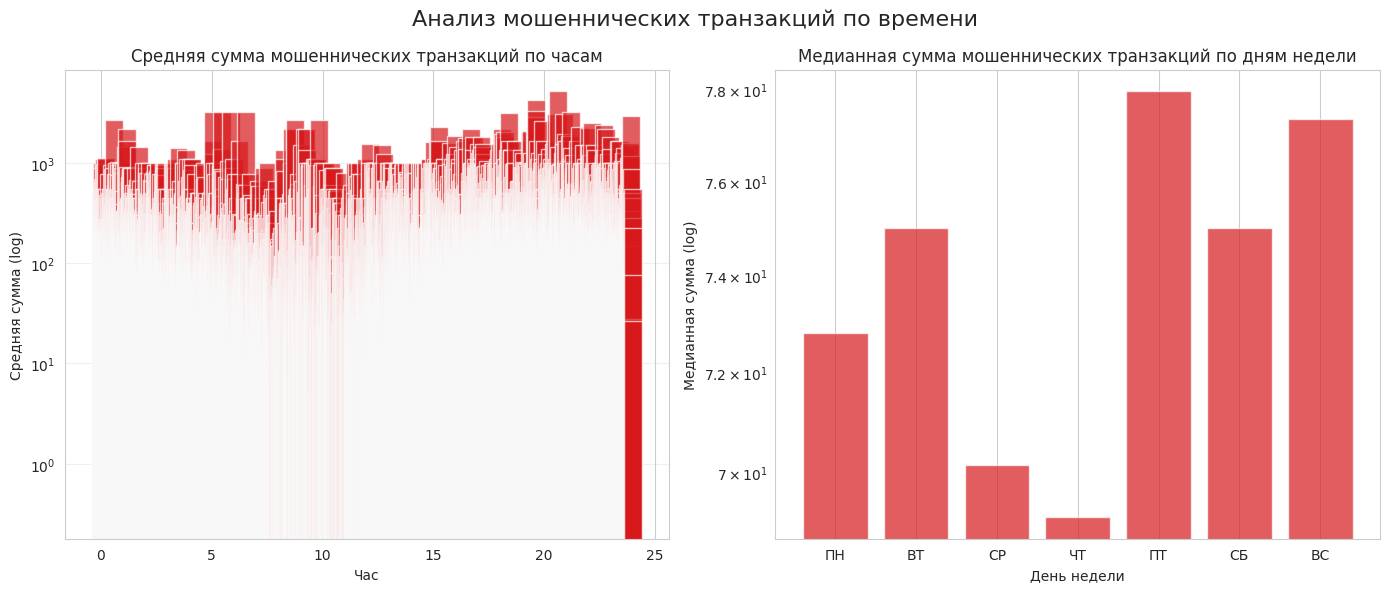

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
# cредняя сумма по часам
ax1 = axes[0]
ax1.bar(agg_hour['TransactionHour'], agg_hour['mean_amt'], color='#d7191c', alpha=0.7)
ax1.set_yscale('log')
ax1.set_title('Средняя сумма мошеннических транзакций по часам', fontsize=12)
ax1.set_xlabel('Час')
ax1.set_ylabel('Средняя сумма (log)')
ax1.grid(axis='y', alpha=0.3)

# сумма по дням недели
ax2 = axes[1]
ax2.bar(agg_week['TransactionDayOfWeek'], agg_week['median_amt'], color='#d7191c', alpha=0.7)
ax2.set_yscale('log')
ax2.set_title('Медианная сумма мошеннических транзакций по дням недели', fontsize=12)
ax2.set_xlabel('День недели')
ax2.set_ylabel('Медианная сумма (log)')
ax2.set_xticks(range(7))
ax2.set_xticklabels(['ПН', 'ВТ', 'СР', 'ЧТ', 'ПТ', 'СБ', 'ВС'])
ax2.grid(axis='y', alpha=0.3)

plt.suptitle('Анализ мошеннических транзакций по времени', fontsize=16)
plt.tight_layout()
plt.show()

#### **Анализ мошенничества по продуктам**

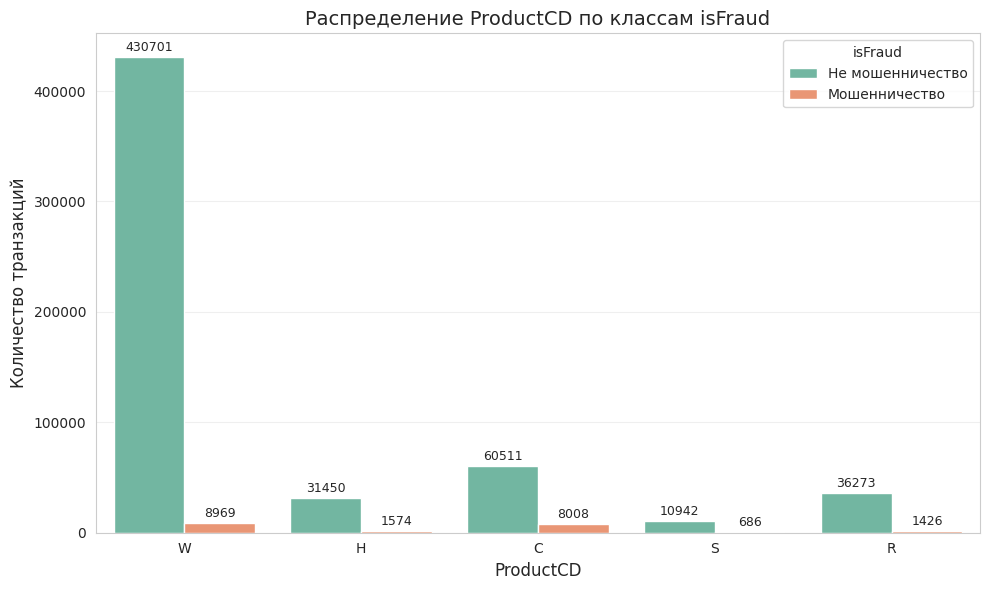

In [26]:
plt.figure(figsize=(10, 6))
ax = sns.countplot(data=train_data, x='ProductCD', hue='isFraud', palette='Set2')
plt.title('Распределение ProductCD по классам isFraud', fontsize=14)
plt.xlabel('ProductCD', fontsize=12)
plt.ylabel('Количество транзакций', fontsize=12)
plt.grid(axis='y', alpha=0.3)
plt.legend(title='isFraud', labels=['Не мошенничество', 'Мошенничество'])

# значения на столбцы для каждого класса
for container in ax.containers:
    ax.bar_label(container, fmt='%d', fontsize=9, padding=2)

plt.tight_layout()
plt.show()


Больше всего мошшеничества было замечено по продукту W и С.

In [27]:
#  доля мошенничества для каждого ProductCD
fraud_by_product = train_data.groupby('ProductCD')['isFraud'].mean().reset_index()
fraud_by_product.columns = ['ProductCD', 'fraud_rate']
# сортировка по убыванию
fraud_by_product = fraud_by_product.sort_values('fraud_rate', ascending=False)
fraud_by_product

,ProductCD,fraud_rate
0,C,0.116873
3,S,0.058996
1,H,0.047662
2,R,0.037826
4,W,0.020399


#### **Значения по картам**

In [28]:
def resumetable_simple(df):
    summary = pd.DataFrame({
        'dtype': df.dtypes,
        'count': df.count(),
        'unique': df.nunique(),
        'missing': df.isnull().sum(),
        'mean': df.mean(numeric_only=True),
        'std': df.std(numeric_only=True),
        'min': df.min(numeric_only=True),
        'max': df.max(numeric_only=True)
    })
    return summary

# Применение
result = resumetable_simple(train_data[['card1', 'card2', 'card3', 'card4', 'card5', 'card6']])
result

,dtype,count,unique,missing,mean,std,min,max
card1,int64,590540,13553,0,9898.734658,4901.170153,1000.0,18396.0
card2,float64,581607,500,8933,362.555488,157.793246,100.0,600.0
card3,float64,588975,114,1565,153.194925,11.336444,100.0,231.0
card4,object,588963,4,1577,NaN,NaN,NaN,NaN
card5,float64,586281,119,4259,199.278897,41.244453,100.0,237.0
card6,object,588969,4,1571,NaN,NaN,NaN,NaN


Имеются пустые значения в картах, стандартное отклонение в первой карте превалирует над остальными, большой разброс, разный тип данных: строки и действительные числа.

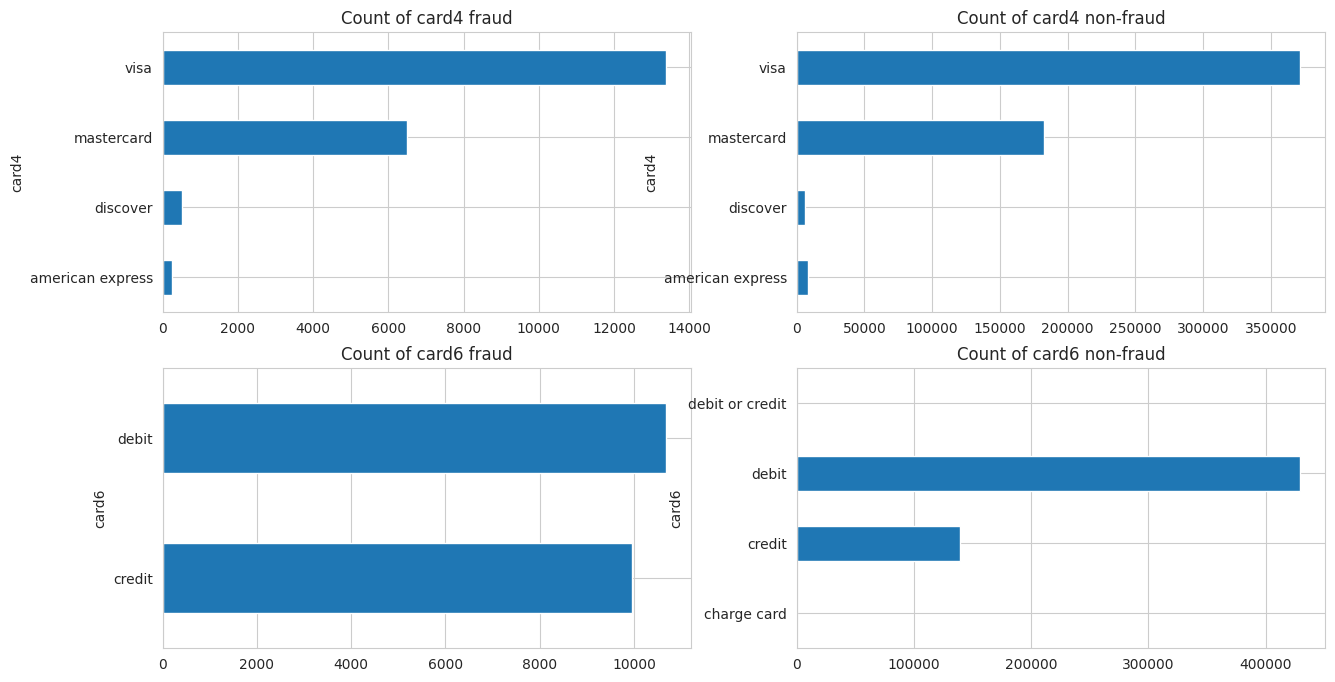

In [29]:
train_transaction_fr = train_transaction.loc[train_transaction['isFraud'] == 1]
train_transaction_nofr = train_transaction.loc[train_transaction['isFraud'] == 0]
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(15, 8))
train_transaction_fr.groupby('card4')['card4'].count().plot(kind='barh', ax=ax1, title='Count of card4 fraud')
train_transaction_nofr.groupby('card4')['card4'].count().plot(kind='barh', ax=ax2, title='Count of card4 non-fraud')
train_transaction_fr.groupby('card6')['card6'].count().plot(kind='barh', ax=ax3, title='Count of card6 fraud')
train_transaction_nofr.groupby('card6')['card6'].count().plot(kind='barh', ax=ax4, title='Count of card6 non-fraud')
plt.show()

#### **Информация об устройстве**

Найдем информацию о потенциальном клиенте-мошеннике о устройству.

In [30]:
train_identity = train_identity.merge(train_data[['TransactionID','TransactionDT','isFraud']], on=['TransactionID'])

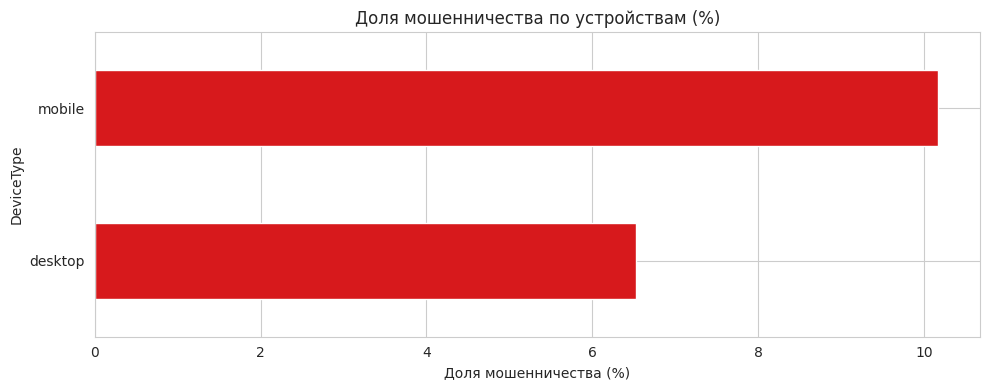

In [31]:
train_identity.groupby('DeviceType')['isFraud'].mean().mul(100) \
    .sort_values() \
    .plot(kind='barh', figsize=(10, 4),
          title='Доля мошенничества по устройствам (%)',
          color='#d7191c')
plt.xlabel('Доля мошенничества (%)')
plt.tight_layout()
plt.show()

Мошеннические транзакции чаще были совершены именно с мобильных устройств, чем с компьютера или ноутбука.

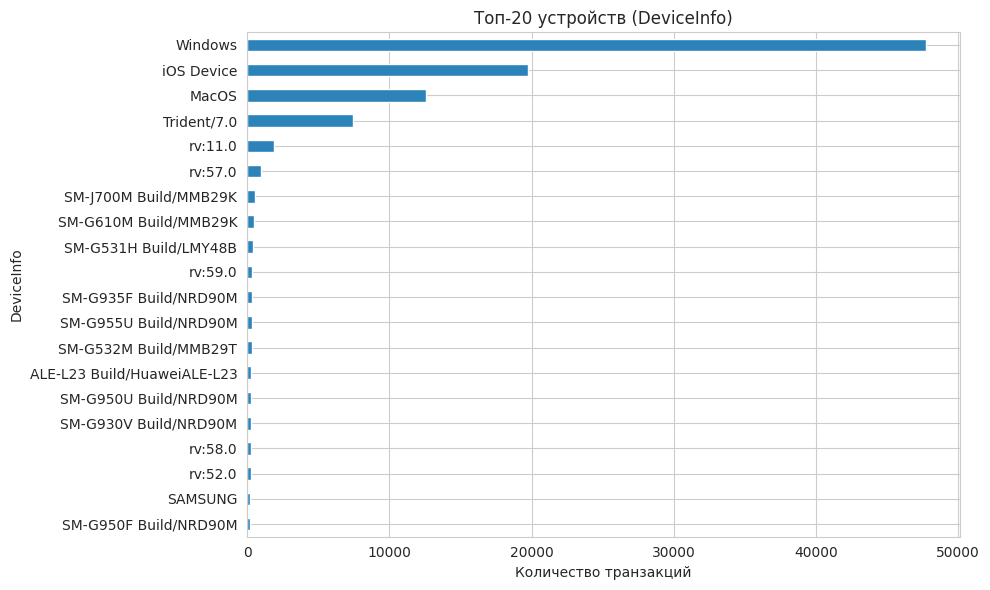

In [32]:
train_identity['DeviceInfo'].value_counts() \
    .head(20) \
    .plot(kind='barh', figsize=(10, 6),
          title='Топ-20 устройств (DeviceInfo)',
          color='#2b83ba')
plt.xlabel('Количество транзакций')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

Чаще всего мошенниками оказывались пользователи таких систем, как Windows, MacOS, iOS Device, Trident/7.0

# **Feature Enginering**

In [33]:
print(train_data.columns.tolist())

['TransactionID', 'isFraud', 'TransactionDT', 'TransactionAmt', 'ProductCD', 'card1', 'card2', 'card3', 'card4', 'card5', 'card6', 'addr1', 'addr2', 'dist1', 'dist2', 'P_emaildomain', 'R_emaildomain', 'C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'C8', 'C9', 'C10', 'C11', 'C12', 'C13', 'C14', 'D1', 'D2', 'D3', 'D4', 'D5', 'D6', 'D7', 'D8', 'D9', 'D10', 'D11', 'D12', 'D13', 'D14', 'D15', 'M1', 'M2', 'M3', 'M4', 'M5', 'M6', 'M7', 'M8', 'M9', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'V29', 'V30', 'V31', 'V32', 'V33', 'V34', 'V35', 'V36', 'V37', 'V38', 'V39', 'V40', 'V41', 'V42', 'V43', 'V44', 'V45', 'V46', 'V47', 'V48', 'V49', 'V50', 'V51', 'V52', 'V53', 'V54', 'V55', 'V56', 'V57', 'V58', 'V59', 'V60', 'V61', 'V62', 'V63', 'V64', 'V65', 'V66', 'V67', 'V68', 'V69', 'V70', 'V71', 'V72', 'V73', 'V74', 'V75', 'V76', 'V77', 'V78', 'V79', 'V80', 'V81', 'V

In [34]:
print(test_data.columns.tolist())

['TransactionID', 'TransactionDT', 'TransactionAmt', 'ProductCD', 'card1', 'card2', 'card3', 'card4', 'card5', 'card6', 'addr1', 'addr2', 'dist1', 'dist2', 'P_emaildomain', 'R_emaildomain', 'C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'C8', 'C9', 'C10', 'C11', 'C12', 'C13', 'C14', 'D1', 'D2', 'D3', 'D4', 'D5', 'D6', 'D7', 'D8', 'D9', 'D10', 'D11', 'D12', 'D13', 'D14', 'D15', 'M1', 'M2', 'M3', 'M4', 'M5', 'M6', 'M7', 'M8', 'M9', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'V29', 'V30', 'V31', 'V32', 'V33', 'V34', 'V35', 'V36', 'V37', 'V38', 'V39', 'V40', 'V41', 'V42', 'V43', 'V44', 'V45', 'V46', 'V47', 'V48', 'V49', 'V50', 'V51', 'V52', 'V53', 'V54', 'V55', 'V56', 'V57', 'V58', 'V59', 'V60', 'V61', 'V62', 'V63', 'V64', 'V65', 'V66', 'V67', 'V68', 'V69', 'V70', 'V71', 'V72', 'V73', 'V74', 'V75', 'V76', 'V77', 'V78', 'V79', 'V80', 'V81', 'V82', 'V83',

In [35]:
# для выявление подозрительных сумм
train_data['TransactionAmt_median_card1'] = train_data['TransactionAmt'] / train_data.groupby(['card1'])['TransactionAmt'].transform('median')
train_data['TransactionAmt_median_card4'] = train_data['TransactionAmt'] / train_data.groupby(['card4'])['TransactionAmt'].transform('median')
train_data['TransactionAmt_std_card1'] = train_data['TransactionAmt'] / train_data.groupby(['card1'])['TransactionAmt'].transform('std')
train_data['TransactionAmt_std_card4'] = train_data['TransactionAmt'] / train_data.groupby(['card4'])['TransactionAmt'].transform('std')

test_data['TransactionAmt_median_card1'] = test_data['TransactionAmt'] / test_data.groupby(['card1'])['TransactionAmt'].transform('median')
test_data['TransactionAmt_median_card4'] = test_data['TransactionAmt'] / test_data.groupby(['card4'])['TransactionAmt'].transform('median')
test_data['TransactionAmt_std_card1'] = test_data['TransactionAmt'] / test_data.groupby(['card1'])['TransactionAmt'].transform('std')
test_data['TransactionAmt_std_card4'] = test_data['TransactionAmt'] / test_data.groupby(['card4'])['TransactionAmt'].transform('std')

In [36]:
# для выявления подозрительных email (разделение email-адресов на составные части)
train_data[['P_emaildomain_1', 'P_emaildomain_2', 'P_emaildomain_3']] = train_data['P_emaildomain'].str.split('.', expand=True)
train_data[['R_emaildomain_1', 'R_emaildomain_2', 'R_emaildomain_3']] = train_data['R_emaildomain'].str.split('.', expand=True)
test_data[['P_emaildomain_1', 'P_emaildomain_2', 'P_emaildomain_3']] = test_data['P_emaildomain'].str.split('.', expand=True)
test_data[['R_emaildomain_1', 'R_emaildomain_2', 'R_emaildomain_3']] = test_data['R_emaildomain'].str.split('.', expand=True)

In [37]:
train_data['TransactionAmt'] = np.log(train_data['TransactionAmt'])
test_data['TransactionAmt'] = np.log(test_data['TransactionAmt'])

# **Кодирование категориальных признаков**

In [38]:
# приведу два датасета к одному формату, так как id отличаются
def rename_id_columns(df):
    rename_dict = {}
    for col in df.columns:
        # 'id-01' - 'id_01'
        if col.startswith('id-'):
            rename_dict[col] = col.replace('id-', 'id_')
    return df.rename(columns=rename_dict)

train_data = rename_id_columns(train_data)
test_data = rename_id_columns(test_data)
print("id_01 в train_identity:", 'id_01' in train_data.columns)
print("id_01 в test_identity:", 'id_01' in test_data.columns)

id_01 в train_identity: True
id_01 в test_identity: True


In [39]:
# Label Encoding
from sklearn.preprocessing import LabelEncoder
from sklearn import preprocessing
# заполняю пропуски
for f in train_data.drop('isFraud', axis=1).columns:
    if train_data[f].dtype=='object' or test_data[f].dtype=='object':
        lbl = preprocessing.LabelEncoder()
        lbl.fit(list(train_data[f].values) + list(test_data[f].values))
        train_data[f] = lbl.transform(list(train_data[f].values))
        test_data[f] = lbl.transform(list(test_data[f].values))

# **Заполнение пропусков**

In [40]:
missing_flag = train_data.isnull().any(axis=1).astype(int)
fraud_by_missing = train_data.groupby(missing_flag)['isFraud'].mean()
print("Доля мошенничества по наличию пропусков:", fraud_by_missing)

Доля мошенничества по наличию пропусков: 1    0.03499
Name: isFraud, dtype: float64


In [41]:
# Количество пропусков в каждой колонке
missing_train = train_data.isnull().sum()
#missing_test = test_data.isnull().sum()
# Только колонки с пропусками
missing = missing_train[missing_train > 0].sort_values(ascending=False)

print(f"Колонок с пропусками: {len(missing)}")
print("\nТоп-20 колонок с пропусками:")
print(missing.head(20))

Колонок с пропусками: 387

Топ-20 колонок с пропусками:
id_24    585793
id_25    585408
id_08    585385
id_07    585385
id_21    585381
id_26    585377
id_22    585371
dist2    552913
D7       551623
id_18    545427
D13      528588
D14      528353
D12      525823
id_03    524216
id_04    524216
D6       517353
id_09    515614
D8       515614
D9       515614
id_10    515614
dtype: int64


# **Масштабирование, PCA, заполнение пропусков**

In [42]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler
# слишком много значений V, оставлю до V15, остальное - снижаем размерность
v_cols = [f'V{i}' for i in range(16, 340)]
v_cols = [col for col in v_cols if col in train_data.columns and col in test_data.columns]
print(f"V-признаков для PCA: {len(v_cols)}")
print(f"Первый: {v_cols[0]}, Последний: {v_cols[-1]}")

V-признаков для PCA: 324
Первый: V16, Последний: V339


In [43]:
X_train = train_data[v_cols].copy()
X_test = test_data[v_cols].copy()

In [44]:
# заполнение пропусков, создается отдельное значение для пустых значений, которое не пересекается с реальными данными
train_min = X_train.min()
X_train = X_train.fillna(train_min - 2)
X_test = X_test.fillna(train_min - 2)
scaler = MinMaxScaler(feature_range=(0, 1))
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [45]:
pca = PCA(n_components=30, random_state=42)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

In [46]:
# dataframe
pca_cols = [f'PCA_V_{i}' for i in range(30)]
train_pca_df = pd.DataFrame(X_train_pca, columns=pca_cols, index=train_data.index)
test_pca_df = pd.DataFrame(X_test_pca, columns=pca_cols, index=test_data.index)

# удаление v-признаков
train_data = train_data.drop(columns=v_cols)
test_data = test_data.drop(columns=v_cols)

# объединение
train_data = pd.concat([train_data, train_pca_df], axis=1)
test_data = pd.concat([test_data, test_pca_df], axis=1)

# **Разделение на train/test**

In [47]:
# 1. сортирую train по времени
train_sorted = train_data.sort_values('TransactionDT')
X = train_sorted.drop(['isFraud', 'TransactionDT'], axis=1)
y = train_sorted['isFraud']
X_test = test_data.drop(['TransactionDT'], axis=1)

In [48]:
# Очистка
X = X.replace([np.inf, -np.inf], np.nan)
X_test = X_test.replace([np.inf, -np.inf], np.nan)

# scale_pos_weight
scale_pos_weight = (y == 0).sum() / (y == 1).sum()
print(f"scale_pos_weight: {scale_pos_weight:.2f}")

scale_pos_weight: 27.58


# **Hyperopt (подбор гиперпараметров)**

In [49]:
!pip install hyperopt
from hyperopt import hp, fmin, tpe, space_eval, STATUS_OK, Trials
from sklearn.model_selection import StratifiedGroupKFold, TimeSeriesSplit
import xgboost as xgb
from xgboost import plot_importance
from sklearn.metrics import roc_auc_score
from sklearn.metrics import average_precision_score, precision_recall_curve
from catboost import CatBoostClassifier
from sklearn.model_selection import cross_val_score
import time
from xgboost import XGBClassifier
import gc

In [50]:
def objective(params):
    time1 = time.time()
    
    params_clean = {
        'n_estimators': int(params['n_estimators']),
        'max_depth': int(params['max_depth']),
        'learning_rate': float(params['learning_rate']),
        'subsample': float(params['subsample']),
        'reg_alpha': float(params['reg_alpha']),
        'reg_lambda': float(params['reg_lambda']),
        'min_child_weight': float(params['min_child_weight']),
    }
    print(f"params = {params_clean}")
    
    FOLDS = 5
    tss = TimeSeriesSplit(n_splits=FOLDS)
    
    roc_auc_mean = 0
    pr_auc_mean = 0
    
    for fold, (tr_idx, val_idx) in enumerate(tss.split(X, y)):
        clf = xgb.XGBClassifier(
            **params_clean,
            scale_pos_weight=scale_pos_weight,
            tree_method='hist',
            eval_metric='auc',
            random_state=42,
            n_jobs=-1,
            use_label_encoder=False
        )
        
        X_tr, X_vl = X.iloc[tr_idx, :], X.iloc[val_idx, :]
        y_tr, y_vl = y.iloc[tr_idx], y.iloc[val_idx]
        
        clf.fit(X_tr, y_tr, verbose=False)
        
        y_pred = clf.predict_proba(X_vl)[:, 1]
        
        roc_auc = roc_auc_score(y_vl, y_pred)
        pr_auc = average_precision_score(y_vl, y_pred)
        
        roc_auc_mean += roc_auc
        pr_auc_mean += pr_auc
        
        print(f'Fold {fold+1}: ROC-AUC={roc_auc:.4f} | PR-AUC={pr_auc:.4f}')
    
    time2 = time.time() - time1
    mean_roc_auc = roc_auc_mean / FOLDS
    mean_pr_auc = pr_auc_mean / FOLDS
    
    print(f"Total Time: {time2 / 60:.2f} min")
    print(f"Mean ROC-AUC: {mean_roc_auc:.4f}")
    print(f"Mean PR-AUC: {mean_pr_auc:.4f}")
    
    gc.collect()
    
    return {'loss': -mean_roc_auc,'status': STATUS_OK, 'roc_auc': mean_roc_auc, 'pr_auc': mean_pr_auc,'time': time2,}
space = {
    'n_estimators': hp.quniform('n_estimators', 100, 500, 20),
    'max_depth': hp.quniform('max_depth', 3, 15, 2),
    'learning_rate': hp.uniform('learning_rate', 0.001, 0.1),
    'subsample': hp.uniform('subsample', 0.5, 1.0),  
    # L1 регуляризация
    'reg_alpha': hp.uniform('reg_alpha', 0.001, 0.1),
    # L2 регуляризация
    'reg_lambda': hp.uniform('reg_lambda', 0.001, 0.1),
    # Минимальный вес в листе
    'min_child_weight': hp.quniform('min_child_weight', 1, 10, 1),
}

In [51]:
trials = Trials()
best_params = fmin(
    fn=objective,
    space=space,
    algo=tpe.suggest,
    max_evals=10,
    trials=trials
)
print(f"Лучшие параметры (Hyperopt): {best_params}")

params = {'n_estimators': 480, 'max_depth': 12, 'learning_rate': 0.027756636908878602, 'subsample': 0.9045879105751998, 'reg_alpha': 0.08096223594944382, 'reg_lambda': 0.00938884243106861, 'min_child_weight': 1.0}
Fold 1: ROC-AUC=0.8747 | PR-AUC=0.5265
Fold 2: ROC-AUC=0.8762 | PR-AUC=0.5528
Fold 3: ROC-AUC=0.8630 | PR-AUC=0.4988
Fold 4: ROC-AUC=0.8899 | PR-AUC=0.5362
Fold 5: ROC-AUC=0.8992 | PR-AUC=0.5566
Total Time: 7.94 min
Mean ROC-AUC: 0.8806
Mean PR-AUC: 0.5342
params = {'n_estimators': 220, 'max_depth': 10, 'learning_rate': 0.06800853520639924, 'subsample': 0.9391041669051556, 'reg_alpha': 0.07158416952044042, 'reg_lambda': 0.04200700805366582, 'min_child_weight': 6.0}
Fold 1: ROC-AUC=0.8708 | PR-AUC=0.5203
Fold 2: ROC-AUC=0.8791 | PR-AUC=0.5600
Fold 3: ROC-AUC=0.8723 | PR-AUC=0.5177
Fold 4: ROC-AUC=0.9038 | PR-AUC=0.5561
Fold 5: ROC-AUC=0.9019 | PR-AUC=0.5544
Total Time: 2.34 min
Mean ROC-AUC: 0.8856
Mean PR-AUC: 0.5417
params = {'n_estimators': 180, 'max_depth': 8, 'learning_ra

In [52]:
# Извлечение лучшего результата
best_trial = trials.best_trial
best_roc_auc = best_trial['result']['roc_auc']
best_pr_auc = best_trial['result']['pr_auc']
best_loss = best_trial['result']['loss']
best_time = best_trial['result']['time']
# DataFrame
best_result_df = pd.DataFrame({
    'Метрика': ['ROC-AUC', 'PR-AUC', 'Loss', 'Time (min)'],
    'Значение': [
        round(best_roc_auc, 4),
        round(best_pr_auc, 4),
        round(best_loss, 4),
        round(best_time / 60, 2),
    ]
})
print("ЛУЧШИЙ РЕЗУЛЬТАТ:")
print(best_result_df.to_string(index=False))

ЛУЧШИЙ РЕЗУЛЬТАТ:
   Метрика  Значение
   ROC-AUC    0.8946
    PR-AUC    0.5618
      Loss   -0.8946
Time (min)    3.5200


# **Обучение финальной модели XGB**

In [53]:
final_params = {
    'n_estimators': int(best_params['n_estimators']),
    'max_depth': int(best_params['max_depth']),
    'learning_rate': float(best_params['learning_rate']),
    'subsample': float(best_params['subsample']),
    'reg_alpha': float(best_params['reg_alpha']),
    'reg_lambda': float(best_params['reg_lambda']),
    'min_child_weight': float(best_params['min_child_weight']),
    'scale_pos_weight': scale_pos_weight,
    'tree_method': 'hist',
    'eval_metric': 'auc',
    'random_state': 42,
    'n_jobs': -1,
    'use_label_encoder': False
}

final_model = xgb.XGBClassifier(**final_params)
final_model.fit(X, y)

y_test_pred = final_model.predict_proba(X_test)[:, 1]

In [54]:
print(f"ROC-AUC: {best_roc_auc:.4f}")
print(f"PR-AUC:  {best_pr_auc:.4f}")

ROC-AUC: 0.8946
PR-AUC:  0.5618


# **Важность признаков**

In [55]:
feature_importance = final_model.get_booster().get_score(importance_type="weight")
keys = list(feature_importance.keys())
values = list(feature_importance.values())

data = pd.DataFrame(
    data=values, 
    index=keys, 
    columns=["score"]
).sort_values(by="score", ascending=False)

In [56]:
data.head(30)

,score
card1,4918.0
TransactionID,4364.0
card2,4221.0
TransactionAmt_std_card1,4046.0
addr1,3897.0
TransactionHour,3853.0
TransactionAmt_median_card1,2916.0
D15,2306.0
C13,2084.0
dist1,2049.0


# **CatBoost**

In [57]:
from catboost import CatBoostClassifier

In [58]:
train_sorted_catboost = train_data.sort_values('TransactionDT')
X = train_sorted_catboost.drop(['isFraud', 'TransactionDT'], axis=1)
y = train_sorted_catboost['isFraud']
X_test_catboost = test_data.drop(['TransactionDT'], axis=1)

In [59]:
# Очистка от inf (CatBoost не работает с inf, но работает с NaN)
X = X.replace([np.inf, -np.inf], np.nan)
X_test = X_test.replace([np.inf, -np.inf], np.nan)

In [60]:
def objective_catboost(params):
    time1 = time.time()
    
    params_clean = {
        'iterations': int(params['iterations']),
        'depth': int(params['depth']),
        'learning_rate': float(params['learning_rate']),
        'l2_leaf_reg': float(params['l2_leaf_reg']),
        'bagging_temperature': float(params['bagging_temperature']),
        'random_strength': float(params['random_strength']),
    }
    print(f"params = {params_clean}")
    
    FOLDS = 5
    tss = TimeSeriesSplit(n_splits=FOLDS)
    
    roc_auc_mean = 0
    pr_auc_mean = 0
    
    for fold, (tr_idx, val_idx) in enumerate(tss.split(X, y)):
        cat = CatBoostClassifier(
            **params_clean,
            scale_pos_weight=scale_pos_weight,
            eval_metric='AUC',
            loss_function='Logloss',
            random_seed=42,
            verbose=False,
            task_type='CPU',                    
            thread_count=-1
        )
        
        X_tr, X_vl = X.iloc[tr_idx], X.iloc[val_idx]
        y_tr, y_vl = y.iloc[tr_idx], y.iloc[val_idx]
        
        cat.fit(X_tr, y_tr, verbose=False)
        
        y_pred = cat.predict_proba(X_vl)[:, 1]
        
        roc_auc = roc_auc_score(y_vl, y_pred)
        pr_auc = average_precision_score(y_vl, y_pred)
        
        roc_auc_mean += roc_auc
        pr_auc_mean += pr_auc
        
        print(f'Fold {fold+1}: ROC-AUC={roc_auc:.4f} | PR-AUC={pr_auc:.4f}')
    
    time2 = time.time() - time1
    mean_roc_auc = roc_auc_mean / FOLDS
    mean_pr_auc = pr_auc_mean / FOLDS
    
    print(f"Total Time: {time2 / 60:.2f} min")
    print(f"Mean ROC-AUC: {mean_roc_auc:.4f}")
    print(f"Mean PR-AUC: {mean_pr_auc:.4f}")
    
    gc.collect()
    
    return {'loss': -mean_roc_auc,'status': STATUS_OK, 'roc_auc': mean_roc_auc, 'pr_auc': mean_pr_auc,'time': time2,}
space = {
    # Количество деревьев
    'iterations': hp.quniform('iterations', 300, 600, 30),
    # Глубина
    'depth': hp.quniform('depth', 3, 10, 1),
    # Learning rate
    'learning_rate': hp.uniform('learning_rate', 0.001, 0.1),
    # L2 регуляризация
    'l2_leaf_reg': hp.uniform('l2_leaf_reg', 0.01, 1),
    # Bagging (0 = без, 1 = стандарт)
    'bagging_temperature': hp.uniform('bagging_temperature', 0.5, 1),
    # Random strength
    'random_strength': hp.uniform('random_strength', 1, 3),
}

In [61]:
trials = Trials()
best_params_cat = fmin(
    fn=objective_catboost,
    space=space,
    algo=tpe.suggest,
    max_evals=10,
    trials=trials
)
print(f"Лучшие параметры (Hyperopt): {best_params_cat}")

params = {'iterations': 540, 'depth': 6, 'learning_rate': 0.01908133681460773, 'l2_leaf_reg': 0.6169054008046773, 'bagging_temperature': 0.8456443986312678, 'random_strength': 2.654697901409357}
Fold 1: ROC-AUC=0.8746 | PR-AUC=0.4908
Fold 2: ROC-AUC=0.8757 | PR-AUC=0.5153
Fold 3: ROC-AUC=0.8746 | PR-AUC=0.4733
Fold 4: ROC-AUC=0.8812 | PR-AUC=0.4993
Fold 5: ROC-AUC=0.8779 | PR-AUC=0.4474
Total Time: 3.86 min
Mean ROC-AUC: 0.8768
Mean PR-AUC: 0.4852
params = {'iterations': 570, 'depth': 7, 'learning_rate': 0.010479758160293388, 'l2_leaf_reg': 0.1372530789543252, 'bagging_temperature': 0.5294412559495913, 'random_strength': 1.7740316452680205}
Fold 1: ROC-AUC=0.8743 | PR-AUC=0.4892
Fold 2: ROC-AUC=0.8802 | PR-AUC=0.5128
Fold 3: ROC-AUC=0.8747 | PR-AUC=0.4727
Fold 4: ROC-AUC=0.8815 | PR-AUC=0.4952
Fold 5: ROC-AUC=0.8794 | PR-AUC=0.4513
Total Time: 4.91 min
Mean ROC-AUC: 0.8780
Mean PR-AUC: 0.4842
params = {'iterations': 600, 'depth': 4, 'learning_rate': 0.08084511207292745, 'l2_leaf_reg': 

In [62]:
# Извлечение лучшего результата
best_trial = trials.best_trial
best_roc_auc = best_trial['result']['roc_auc']
best_pr_auc = best_trial['result']['pr_auc']
best_loss = best_trial['result']['loss']
best_time = best_trial['result']['time']
# DataFrame
best_result_df = pd.DataFrame({
    'Метрика': ['ROC-AUC', 'PR-AUC', 'Loss', 'Time (min)'],
    'Значение': [
        round(best_roc_auc, 4),
        round(best_pr_auc, 4),
        round(best_loss, 4),
        round(best_time / 60, 2),
    ]
})
print("ЛУЧШИЙ РЕЗУЛЬТАТ:")
print(best_result_df.to_string(index=False))

ЛУЧШИЙ РЕЗУЛЬТАТ:
   Метрика  Значение
   ROC-AUC    0.8864
    PR-AUC    0.4925
      Loss   -0.8864
Time (min)    3.7600


# **Обучение финальной модели Catboost**

In [63]:
final_params_catboost = {
    'iterations': int(best_params_cat['iterations']), 
    'depth': int(best_params_cat['depth']),             
    'learning_rate': float(best_params_cat['learning_rate']),
    # Регуляризация
    'l2_leaf_reg': float(best_params_cat['l2_leaf_reg']),
    'bagging_temperature': float(best_params_cat['bagging_temperature']),
    'random_strength': float(best_params_cat['random_strength']),
    # Для дисбаланса
    'scale_pos_weight': scale_pos_weight, 
    # Loss и метрика
    'loss_function': 'Logloss',
    'eval_metric': 'AUC',                                  
    # Технические
    'random_seed': 42,                                     
    'task_type': 'CPU',
    'thread_count': -1,
    'verbose': 100
}
final_model_cat = CatBoostClassifier(**final_params_catboost)
final_model_cat.fit(X, y)

y_test_pred_cat = final_model_cat.predict_proba(X_test)[:, 1]

0:	total: 142ms	remaining: 1m 25s
100:	total: 13.8s	remaining: 1m 8s
200:	total: 27.1s	remaining: 53.7s
300:	total: 40.5s	remaining: 40.2s
400:	total: 54.1s	remaining: 26.9s
500:	total: 1m 7s	remaining: 13.4s
599:	total: 1m 21s	remaining: 0us


In [64]:
print(f"ROC-AUC: {best_roc_auc:.4f}")
print(f"PR-AUC:  {best_pr_auc:.4f}")

ROC-AUC: 0.8864
PR-AUC:  0.4925


# **MLP**

In [65]:
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.preprocessing import OrdinalEncoder, StandardScaler
from sklearn.model_selection import TimeSeriesSplit
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    roc_curve, roc_auc_score, average_precision_score,
    classification_report, precision_recall_curve
)
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.utils.class_weight import compute_class_weight

In [66]:
train_sorted = train_data.sort_values('TransactionDT').reset_index(drop=True)
X = train_sorted.drop(['isFraud', 'TransactionDT'], axis=1)
y = train_sorted['isFraud']
X_test = test_data.drop(['TransactionDT'], axis=1)

In [67]:
print(f"X: {X.shape}, y: {y.shape}, X_test: {X_test.shape}")
print(f"Доля мошенничества: {y.mean()*100:.2f}%")

X: (590540, 153), y: (590540,), X_test: (506691, 153)
Доля мошенничества: 3.50%


In [68]:
# общие колонки
common_cols = list(set(X.columns) & set(X_test.columns))
X = X[common_cols]
X_test = X_test[common_cols]

# разделим данные на категориальные и числовые
cat_cols = X.select_dtypes(include='object').columns
num_cols = X.select_dtypes(exclude='object').columns

In [69]:
# ОЧИСТКА ОТ INF
X[num_cols] = X[num_cols].replace([np.inf, -np.inf], np.nan)
X_test[num_cols] = X_test[num_cols].replace([np.inf, -np.inf], np.nan)

In [70]:
from sklearn.model_selection import TimeSeriesSplit

tss = TimeSeriesSplit(n_splits=5)
tr_idx, val_idx = next(tss.split(X, y))

X_train = X.iloc[tr_idx].copy()
y_train = y.iloc[tr_idx].copy()
X_val = X.iloc[val_idx].copy()
y_val = y.iloc[val_idx].copy()

print(f"\nTrain: {X_train.shape}, Val: {X_val.shape}")


Train: (98425, 153), Val: (98423, 153)


In [71]:
# Заполню пропущенные значения медианой
# Категориальные заполню 'missing'
for df in [X_train, X_val, X_test]:
    df[cat_cols] = df[cat_cols].fillna('missing')
# Числовые заполню медианой 
train_median = X_train[num_cols].median()
X_train[num_cols] = X_train[num_cols].fillna(train_median)
X_val[num_cols] = X_val[num_cols].fillna(train_median)
X_test[num_cols] = X_test[num_cols].fillna(train_median)

print(f"Пропусков в X_train: {X_train.isnull().sum().sum()}")
print(f"Пропусков в X_val: {X_val.isnull().sum().sum()}")
print(f"Пропусков в X_test: {X_test.isnull().sum().sum()}")

Пропусков в X_train: 0
Пропусков в X_val: 0
Пропусков в X_test: 0


In [72]:
# Ordinalencoder ДЛЯ КАТЕГОРИАЛЬНЫХ
from sklearn.preprocessing import OrdinalEncoder
encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
X_train_enc = encoder.fit_transform(X_train[cat_cols]).astype('float32')
X_val_enc   = encoder.transform(X_val[cat_cols]).astype('float32')
X_test_enc  = encoder.transform(X_test[cat_cols]).astype('float32')

In [73]:
from sklearn.preprocessing import StandardScaler

In [74]:
# STANDARDSCALER ДЛЯ ЧИСЛОВЫХ
scaler = StandardScaler()
X_train_num = scaler.fit_transform(X_train[num_cols]).astype('float32')
X_val_num   = scaler.transform(X_val[num_cols]).astype('float32')
X_test_num  = scaler.transform(X_test[num_cols]).astype('float32')

In [75]:
# ОБЪЕДИНЕНИЕ
X_train_final = np.hstack([X_train_enc, X_train_num])
X_val_final   = np.hstack([X_val_enc,   X_val_num])
X_test_final  = np.hstack([X_test_enc,  X_test_num])

In [76]:
print(f"\nФинальные данные:")
print(f"  X_train_final: {X_train_final.shape}")
print(f"  X_val_final: {X_val_final.shape}")
print(f"  X_test_final: {X_test_final.shape}")
print(f"  NaN: {np.isnan(X_train_final).sum()}")
print(f"  Inf: {np.isinf(X_train_final).sum()}")
print(f"  Mean: {X_train_final.mean():.4f}")
print(f"  Std: {X_train_final.std():.4f}")


Финальные данные:
  X_train_final: (98425, 153)
  X_val_final: (98423, 153)
  X_test_final: (506691, 153)
  NaN: 0
  Inf: 0
  Mean: -0.0000
  Std: 1.0000


In [77]:
from imblearn.over_sampling import ADASYN # применяются только к train
# сделаем синтетические данные для миноритарных классов

adasyn = ADASYN(sampling_strategy=0.3, random_state=42)
X_train_resampled, y_train_resampled = adasyn.fit_resample(
    X_train_final, y_train.values
)

In [78]:
np.random.seed(42)

In [79]:
# МОДЕЛЬ MLP
model_1 = Sequential([
    Dense(512, activation='silu', input_shape=(X_train_final.shape[1],)),
    BatchNormalization(),
    Dropout(0.4),

    Dense(256, activation='silu'),
    BatchNormalization(),
    Dropout(0.2),

    Dense(128, activation='silu'),
    BatchNormalization(),
    Dropout(0.2),

    Dense(1, activation='sigmoid')
])

model_1.compile(
    optimizer=tf.keras.optimizers.AdamW(learning_rate=1e-3, weight_decay=1e-3,epsilon=1e-7, clipnorm=1.0),
    loss='binary_crossentropy',
    metrics=[
        tf.keras.metrics.AUC(curve='ROC', name='roc_auc'),
        tf.keras.metrics.AUC(curve='PR',  name='pr_auc'),
        tf.keras.metrics.Precision(name='precision'),
        tf.keras.metrics.Recall(name='recall'),
    ]
)

model_1.summary()

I0000 00:00:1791749574.546640      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1791749574.552667      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 512)            │        78,848 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 246,785 (964.00 KB)

 Trainable params: 244,993 (957.00 KB)

 Non-trainable params: 1,792 (7.00 KB)

In [80]:
# Callback
early_stop = EarlyStopping(
    monitor='val_pr_auc',
    patience=6, # сколько эпох ждать перед остановкой, если метрика не улучшается
    mode='max',
    restore_best_weights=True,
    verbose=1,
)

In [81]:
print("Training model...")
history = model_1.fit(
    X_train_resampled, y_train_resampled,
    validation_data=(X_val_final, y_val.values),
    epochs=35,
    batch_size=128,
    callbacks=[early_stop],
    verbose=1
)

Training model...
Epoch 1/35
 55/975 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.7485 - pr_auc: 0.3794 - precision: 0.3187 - recall: 0.5733 - roc_auc: 0.6461

I0000 00:00:1791749585.168070     403 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


975/975 ━━━━━━━━━━━━━━━━━━━━ 20s 12ms/step - loss: 0.3612 - pr_auc: 0.7001 - precision: 0.6790 - recall: 0.5904 - roc_auc: 0.8769 - val_loss: 0.1525 - val_pr_auc: 0.2949 - val_precision: 0.3824 - val_recall: 0.2797 - val_roc_auc: 0.7511
Epoch 2/35
975/975 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 0.2341 - pr_auc: 0.8621 - precision: 0.8089 - recall: 0.7485 - roc_auc: 0.9508 - val_loss: 0.1711 - val_pr_auc: 0.3037 - val_precision: 0.3854 - val_recall: 0.2888 - val_roc_auc: 0.7423
Epoch 3/35
975/975 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - loss: 0.1782 - pr_auc: 0.9156 - precision: 0.8502 - recall: 0.8266 - roc_auc: 0.9720 - val_loss: 0.1709 - val_pr_auc: 0.2933 - val_precision: 0.4277 - val_recall: 0.2737 - val_roc_auc: 0.7365
Epoch 4/35
975/975 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - loss: 0.1449 - pr_auc: 0.9421 - precision: 0.8782 - recall: 0.8644 - roc_auc: 0.9814 - val_loss: 0.1887 - val_pr_auc: 0.2760 - val_precision: 0.4987 - val_recall: 0.2289 - val_roc_auc: 0.7159
Epoch 5/35
975/975 ━━━━━━

In [82]:
# Оценка на валидации
# train оценим на оригинальном train
y_pred_train = model_1.predict(X_train_final).ravel()
y_pred_val   = model_1.predict(X_val_final).ravel()

print(f"TRAIN (orig): ROC-AUC={roc_auc_score(y_train, y_pred_train):.4f}  "
      f"PR-AUC={average_precision_score(y_train, y_pred_train):.4f}")
print(f"VAL:          ROC-AUC={roc_auc_score(y_val,   y_pred_val):.4f}  "
      f"PR-AUC={average_precision_score(y_val,   y_pred_val):.4f}")

3076/3076 ━━━━━━━━━━━━━━━━━━━━ 5s 1ms/step
3076/3076 ━━━━━━━━━━━━━━━━━━━━ 4s 1ms/step
TRAIN (orig): ROC-AUC=0.9974  PR-AUC=0.9339
VAL:          ROC-AUC=0.7513  PR-AUC=0.3091


In [83]:
from sklearn.metrics import classification_report

fpr, tpr, thr_roc = roc_curve(y_val, y_pred_val)
MAX_FPR = 0.01
idx = np.where(fpr <= MAX_FPR)[0][-1]
thr = thr_roc[idx]
print(f"\n@FPR<=1%: threshold={thr:.4f}, recall={tpr[idx]:.4f}")

y_hat = (y_pred_val >= thr).astype(int)
print(classification_report(y_val, y_hat,
      target_names=['Normal', 'Fraud'], digits=4))


@FPR<=1%: threshold=0.2971, recall=0.2728
              precision    recall  f1-score   support

      Normal     0.9751    0.9900    0.9825     95116
       Fraud     0.4868    0.2728    0.3496      3307

    accuracy                         0.9659     98423
   macro avg     0.7309    0.6314    0.6661     98423
weighted avg     0.9587    0.9659    0.9612     98423



3076/3076 ━━━━━━━━━━━━━━━━━━━━ 4s 1ms/step


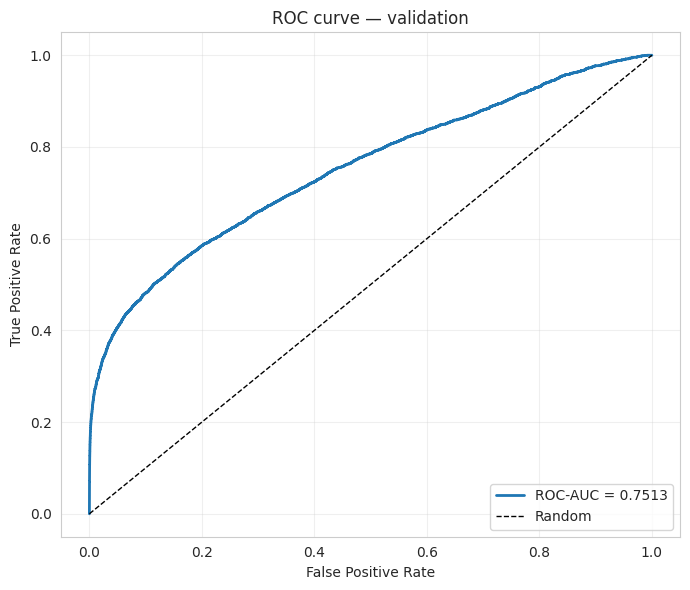

ROC-AUC: 0.7513


In [84]:
y_pred_val = model_1.predict(X_val_final).ravel()
y_true = y_val.values

fpr, tpr, _ = roc_curve(y_true, y_pred_val)
roc_auc = roc_auc_score(y_true, y_pred_val)

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, color='tab:blue', lw=2, label=f'ROC-AUC = {roc_auc:.4f}')
plt.plot([0, 1], [0, 1], 'k--', lw=1, label='Random')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC curve — validation')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(r'D:\ml_projects\roc_val.png', dpi=120, bbox_inches='tight')
plt.show()

print(f"ROC-AUC: {roc_auc:.4f}")

In [85]:
# Предсказание на тесте
y_test_pred = model_1.predict(X_test_final).ravel()

15835/15835 ━━━━━━━━━━━━━━━━━━━━ 21s 1ms/step


In [86]:
submission = pd.DataFrame({
    'TransactionID': test_data['TransactionID'].values,
    'isFraud': y_test_pred
})
submission.to_csv('submission_mlp.csv', index=False)
print(f"\n✅ Submission сохранён: {submission.shape}")
print(submission.head())


✅ Submission сохранён: (506691, 2)
   TransactionID       isFraud
0        3663549  5.109800e-31
1        3663550  2.986797e-27
2        3663551  2.080777e-24
3        3663552  3.660093e-31
4        3663553  9.068608e-30
